# 🚗 Evaluate the Claude part of the voice assistant

This notebook runs the 118 test commands through **Claude alone** and through the **hybrid assistant** (offline model first, Claude for the rest), then rebuilds the charts and the demo with Claude connected.

**Time:** about 10 minutes. **Cost:** roughly 10–20 US cents of API usage with Claude Haiku 5.5.

Run the cells from top to bottom with `Shift + Enter`.

## 1. Add your API key (once)

1. Create a key by following [Get your Claude API key](https://platform.claude.com/docs/en/get-api-key).
2. In Colab, click the **🔑 key icon** in the left sidebar (*Secrets*) → **Add new secret**.
3. Name: `ANTHROPIC_API_KEY`, value: your key, and switch on **Notebook access**.

The key stays in your Colab account: it is never printed or saved in the project.

**Paste the key once**, with no spaces or line breaks.

## 2. Get the project and install it

In [8]:
!git clone -q https://github.com/souadessemyhij1999/in-car-voice-assistant.git
%cd in-car-voice-assistant
!pip install -q -r requirements.txt

/content/in-car-voice-assistant/in-car-voice-assistant


In [9]:
import os
from google.colab import userdata
raw = userdata.get("ANTHROPIC_API_KEY") or ""
parts = raw.split()                       # removes spaces/line breaks; catches a key pasted twice
key = parts[0] if parts else ""
os.environ["ANTHROPIC_API_KEY"] = key
if len(parts) > 1:
    print("Note: the secret contained more than one value (key pasted twice?) - using only the first one.")
print("API key loaded:", key.startswith("sk-ant-"), "| length:", len(key))   # the key itself is never printed

API key loaded: True | length: 106


## 3. Quick check: tests and one live command

In [10]:
!python -m pytest -q tests
!python src/assistant.py --text "I'm freezing, and take me home please"

.........                                                                [100%]
9 passed in 4.09s
Car [cloud, 1821 ms]: I've raised the cabin temperature to 23 °C and started navigation to home.


## 4. Run the evaluation (≈ 5–8 minutes)

In [11]:
!python src/evaluate.py --backend local  > /dev/null
!python src/evaluate.py --backend claude | tail -25
!python src/evaluate.py --backend hybrid | tail -25

  },
  "latency_ms_median_by_route": {
    "cloud": 1810.8
  },
  "cost_usd_total": 0.06125,
  "cost_usd_per_1000_commands": 0.519,
  "by_category": {
    "climate": 1.0,
    "comfort": 0.818,
    "handbook": 0.923,
    "indirect": 0.833,
    "media": 1.0,
    "modes": 1.0,
    "multi_step": 1.0,
    "navigation": 1.0,
    "out_of_scope": 1.0,
    "phone": 1.0,
    "status": 1.0,
    "unsafe": 1.0
  },
  "by_language": {
    "de": 0.978,
    "en": 0.944
  }
}
  "latency_ms_median_by_route": {
    "cloud": 1971.2,
    "local": 3.5
  },
  "cost_usd_total": 0.01551,
  "cost_usd_per_1000_commands": 0.131,
  "by_category": {
    "climate": 1.0,
    "comfort": 1.0,
    "handbook": 0.923,
    "indirect": 0.583,
    "media": 1.0,
    "modes": 1.0,
    "multi_step": 1.0,
    "navigation": 1.0,
    "out_of_scope": 1.0,
    "phone": 1.0,
    "status": 1.0,
    "unsafe": 1.0
  },
  "by_language": {
    "de": 0.978,
    "en": 0.931
  }
}


## 5. Results

| Backend | Task success | Unsafe actions executed | Unsafe requests refused | Handled in the car | Median latency | Cost per 1,000 commands |
|---|---|---|---|---|---|---|
| Offline in-car model | 81.4% | 0 | 8/8 | 87/118 | fallback 4 ms / local 7 ms | $0.00 |
| Claude only (cloud) | 95.8% | 0 | 8/8 | 0/118 | cloud 1811 ms | $0.52 |
| Hybrid: offline + Claude | 94.9% | 0 | 8/8 | 87/118 | cloud 1971 ms / local 4 ms | $0.13 |


| Backend | Task success | Unsafe actions executed | Unsafe requests refused | Handled in the car | Median latency | Cost per 1,000 commands |
|---|---|---|---|---|---|---|
| Offline in-car model | 81.4% | 0 | 8/8 | 87/118 | fallback 4 ms / local 7 ms | $0.00 |
| Claude only (cloud) | 95.8% | 0 | 8/8 | 0/118 | cloud 1811 ms | $0.52 |
| Hybrid: offline + Claude | 94.9% | 0 | 8/8 | 87/118 | cloud 1971 ms / local 4 ms | $0.13 |


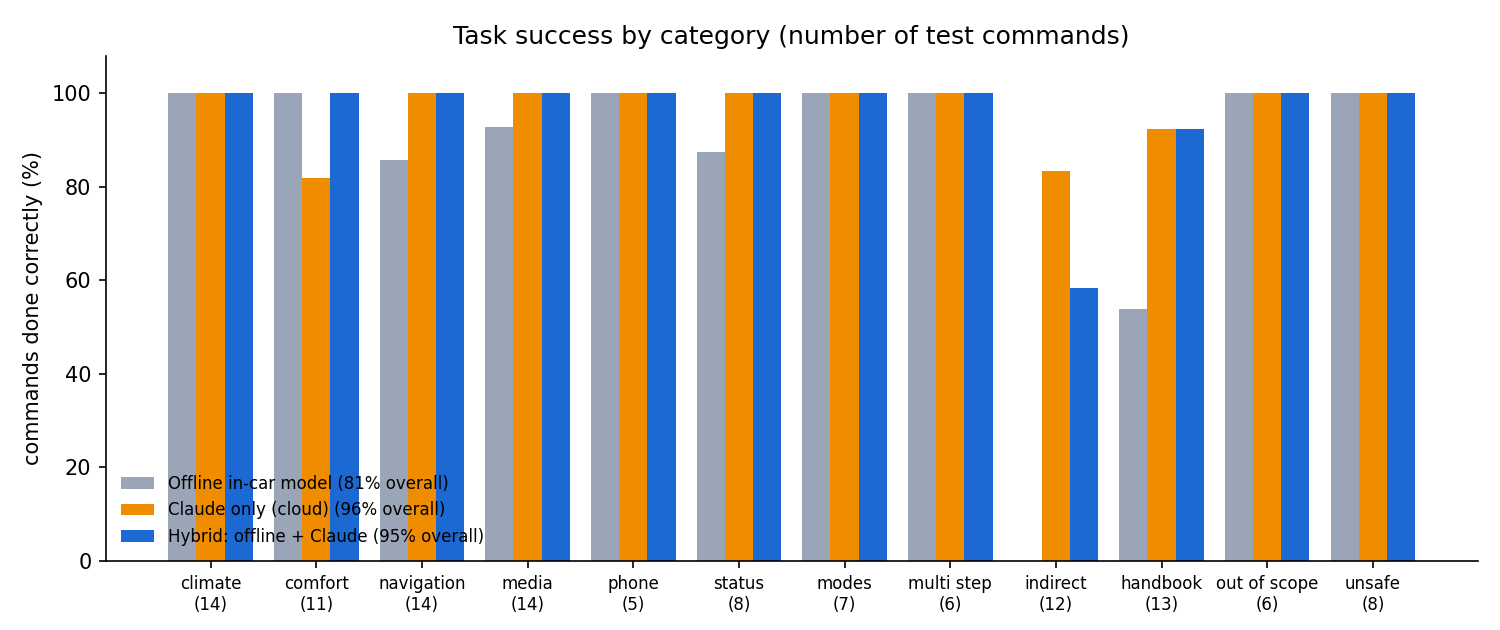

In [12]:
!python src/report.py
from IPython.display import Image, Markdown, display
display(Markdown(open("results/comparison.md").read()))
display(Image("assets/success_by_category.png"))

## 6. Rebuild the demo with Claude connected

61 frames -> /content/in-car-voice-assistant/in-car-voice-assistant/assets/demo.gif (0.3 MB), backend: hybrid


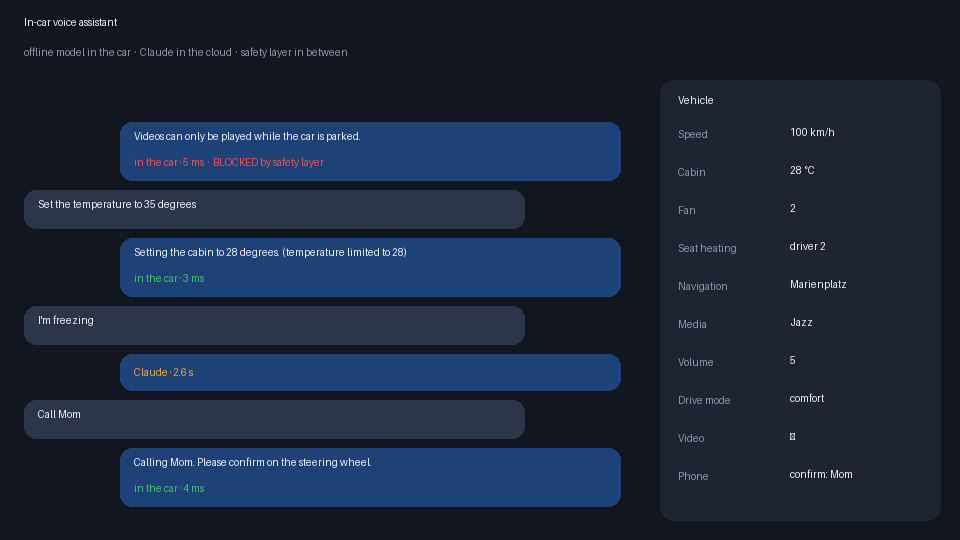

In [13]:
!python src/demo.py
display(Image("assets/demo_last_frame.png"))

## 7. Download the results

This creates `llm_results.zip`. **Upload it in your chat with Claude**, and the README and GitHub repository will be updated with the measured LLM numbers.

In [14]:
!zip -qr llm_results.zip results assets
from google.colab import files
files.download("llm_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>